### Setup and Device Selection

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import random
from pathlib import Path

# Add project root to sys.path
PROJECT_ROOT = Path.cwd().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from src.models import WildfireCNN
from src.dataset import WildfireTensorDataset

def set_seed(seed: int = 42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

# Device selection fallback chain: CUDA -> MPS -> CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"Using NVIDIA GPU (CUDA): {torch.cuda.get_device_name(0)}")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("Using Apple Silicon GPU (Metal Performance Shaders - MPS)")
else:
    device = torch.device("cpu")
    print("No hardware accelerator found. Defaulting to CPU")

Using Apple Silicon GPU (Metal Performance Shaders - MPS)


### Checkpoint Configuration

In [2]:
# --- CHECKPOINT CONFIGURATION (Modify for future iterations/runs) ---
MODEL_NAME = "WildfireCNN"
RUN_TAG = "cnn_baseline_run3_50epochs"
CHECKPOINT_PATH = Path(f"../models/{RUN_TAG}.pt")
BATCH_SIZE = 512

### Load Checkpoint and Memory-Mapped Tensors (`2023 Val` + `2024 Test`)

In [3]:
# Initialize model and load trained weights
model = WildfireCNN().to(device)
state_dict = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
model.load_state_dict(state_dict)
model.eval()
print(f"Loaded checkpoint: {CHECKPOINT_PATH} in eval() mode.")

# Load 2023 Validation set (strictly for threshold calibration)
val_dataset = WildfireTensorDataset(
    "../data/processed/tensors/X_val.npy",
    "../data/processed/tensors/y_val.npy"
)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Load 2024 Independent Holdout Test set
test_dataset = WildfireTensorDataset(
    "../data/processed/tensors/X_test.npy",
    "../data/processed/tensors/y_test.npy"
)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"2023 Val samples  : {len(val_dataset):,}")
print(f"2024 Test samples : {len(test_dataset):,}")

Loaded checkpoint: ../models/cnn_baseline_run3_50epochs.pt in eval() mode.
2023 Val samples  : 1,388,899
2024 Test samples : 1,392,854


### Calibrate Optimal Decision Threshold on 2023 Validation

In [4]:
def run_inference(model, loader, device, desc="Inference"):
    model.eval()
    all_probs = []
    all_targets = []
    
    with torch.no_grad():
        for X_batch, y_batch in tqdm(loader, desc=desc):
            X_batch = X_batch.to(device)
            logits = model(X_batch)
            probs = torch.sigmoid(logits)
            all_probs.extend(probs.cpu().numpy())
            all_targets.extend(y_batch.numpy())
            
    return np.array(all_probs).flatten(), np.array(all_targets).flatten()

# 1. Run inference on 2023 Validation to find best F1 threshold
val_probs, val_targets = run_inference(model, val_loader, device, desc="2023 Val Calibration")

precisions, recalls, thresholds = precision_recall_curve(val_targets, val_probs)
# Compute F1 for each threshold (excluding final sentinel point)
f1_scores = (2 * precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-12)
best_idx = np.argmax(f1_scores)

optimal_threshold = float(thresholds[best_idx])
val_best_f1 = float(f1_scores[best_idx])
val_pr_auc = float(average_precision_score(val_targets, val_probs))
val_roc_auc = float(roc_auc_score(val_targets, val_probs))

print(f"\n--- 2023 Validation Calibration Results ---")
print(f"Verified Val PR-AUC  : {val_pr_auc:.4f}")
print(f"Verified Val ROC-AUC : {val_roc_auc:.4f}")
print(f"Optimal Threshold    : {optimal_threshold:.4f}")
print(f"Max Val F1-Score     : {val_best_f1:.4f} (Precision: {precisions[best_idx]:.4f}, Recall: {recalls[best_idx]:.4f})")

2023 Val Calibration:   0%|          | 0/2713 [00:00<?, ?it/s]


--- 2023 Validation Calibration Results ---
Verified Val PR-AUC  : 0.9232
Verified Val ROC-AUC : 0.9986
Optimal Threshold    : 0.9961
Max Val F1-Score     : 0.9035 (Precision: 0.8731, Recall: 0.9362)


### 2024 Independent Holdout Test Evaluation

In [5]:
# 2. Run inference on 2024 Holdout Test set
test_probs, test_targets = run_inference(model, test_loader, device, desc="2024 Test Evaluation")

test_pr_auc = float(average_precision_score(test_targets, test_probs))
test_roc_auc = float(roc_auc_score(test_targets, test_probs))

# Apply locked 2023 threshold
test_preds_bin = (test_probs >= optimal_threshold).astype(int)
test_targets_bin = test_targets.astype(int)

tn, fp, fn, tp = confusion_matrix(test_targets_bin, test_preds_bin).ravel()
test_precision = float(precision_score(test_targets_bin, test_preds_bin, zero_division=0))
test_recall = float(recall_score(test_targets_bin, test_preds_bin, zero_division=0))
test_f1 = float(f1_score(test_targets_bin, test_preds_bin, zero_division=0))

print(f"\n==========================================")
print(f"2024 HOLDOUT TEST RESULTS: {RUN_TAG}")
print(f"==========================================")
print(f"Test Samples      : {len(test_targets):,} (Fires: {int(test_targets_bin.sum()):,})")
print(f"Locked Threshold  : {optimal_threshold:.4f}")
print(f"Test PR-AUC       : {test_pr_auc:.4f}")
print(f"Test ROC-AUC      : {test_roc_auc:.4f}")
print(f"Precision         : {test_precision:.4f}")
print(f"Recall            : {test_recall:.4f}")
print(f"F1 Score          : {test_f1:.4f}")
print(f"Confusion Matrix  : TP={tp:,} | FP={fp:,} | TN={tn:,} | FN={fn:,}")

2024 Test Evaluation:   0%|          | 0/2721 [00:00<?, ?it/s]


2024 HOLDOUT TEST RESULTS: cnn_baseline_run3_50epochs
Test Samples      : 1,392,854 (Fires: 3,841)
Locked Threshold  : 0.9961
Test PR-AUC       : 0.9148
Test ROC-AUC      : 0.9986
Precision         : 0.8903
Recall            : 0.9104
F1 Score          : 0.9002
Confusion Matrix  : TP=3,497 | FP=431 | TN=1,388,582 | FN=344


### Plot 2024 Test PR Curve and Export Artifacts to `outputs/`

Saved 2024 PR Curve to: ../outputs/cnn_baseline_run3_50epochs_test_2024_pr_curve.png


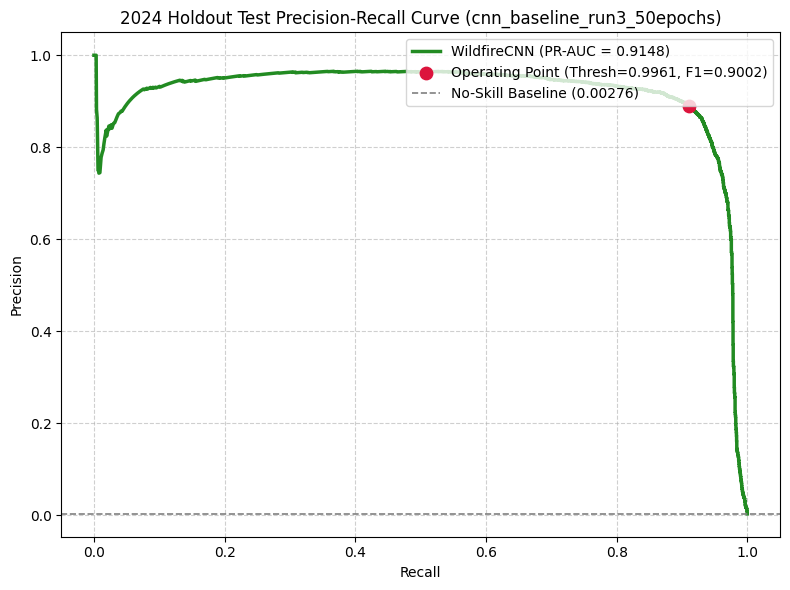

Saved 2024 Test Metrics JSON to: ../outputs/cnn_baseline_run3_50epochs_test_2024_metrics.json


In [6]:
outputs_dir = Path("../outputs")
outputs_dir.mkdir(parents=True, exist_ok=True)

# 1. Plot 2024 Test Precision-Recall Curve
test_prec_curve, test_rec_curve, _ = precision_recall_curve(test_targets_bin, test_probs)
no_skill = test_targets_bin.sum() / len(test_targets_bin)

plt.figure(figsize=(8, 6))
plt.plot(test_rec_curve, test_prec_curve, color="forestgreen", lw=2.5,
         label=f"{MODEL_NAME} (PR-AUC = {test_pr_auc:.4f})")
plt.scatter([test_recall], [test_precision], color="crimson", s=80, zorder=5,
            label=f"Operating Point (Thresh={optimal_threshold:.4f}, F1={test_f1:.4f})")
plt.axhline(no_skill, color="gray", linestyle="--", lw=1.2,
            label=f"No-Skill Baseline ({no_skill:.5f})")

plt.title(f"2024 Holdout Test Precision-Recall Curve ({RUN_TAG})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()

pr_fig_path = outputs_dir / f"{RUN_TAG}_test_2024_pr_curve.png"
plt.savefig(pr_fig_path, dpi=300, bbox_inches="tight")
print(f"Saved 2024 PR Curve to: {pr_fig_path}")
plt.show()

# 2. Export 2024 Test Metrics JSON
test_metrics_summary = {
    "model": MODEL_NAME,
    "run": RUN_TAG,
    "checkpoint_path": str(CHECKPOINT_PATH),
    "evaluated_threshold": optimal_threshold,
    "test_samples": int(len(test_targets_bin)),
    "positive_fires": int(test_targets_bin.sum()),
    "test_pr_auc": test_pr_auc,
    "test_roc_auc": test_roc_auc,
    "precision": test_precision,
    "recall": test_recall,
    "f1_score": test_f1,
    "confusion_matrix": {
        "tp": int(tp),
        "fp": int(fp),
        "tn": int(tn),
        "fn": int(fn)
    }
}

metrics_json_path = outputs_dir / f"{RUN_TAG}_test_2024_metrics.json"
with open(metrics_json_path, "w") as f:
    json.dump(test_metrics_summary, f, indent=4)

print(f"Saved 2024 Test Metrics JSON to: {metrics_json_path}")

### Prevalance-Adjusted (20 X Negative Weighting) Full-Population Comparision

Because `X_val.npy` and `X_test.npy` both contain 100% of fire ignitions and a deterministic 5% `(1/20)` subsample of background negatives, weighting each negative sample by 20.0 reconstructs the full ~27.7M-row California grid prevalence ($\approx 0.0138\%$) without needing to re-run model inference:

In [7]:
# --- CELL 6: PREVALENCE-ADJUSTED (20x NEGATIVE WEIGHTING) EVALUATION ---
# Reconstructs full-population California grid prevalence (~0.0138%) from the 5% negative sample
NEG_WEIGHT = 20.0

val_weights = np.where(val_targets == 1, 1.0, NEG_WEIGHT)
test_weights = np.where(test_targets_bin == 1, 1.0, NEG_WEIGHT)

# 1. Re-calibrate F1 threshold on 2023 Validation under true full-population prevalence
adj_val_prec, adj_val_rec, adj_val_thresh = precision_recall_curve(
    val_targets, val_probs, sample_weight=val_weights
)
adj_val_f1s = (2 * adj_val_prec[:-1] * adj_val_rec[:-1]) / (adj_val_prec[:-1] + adj_val_rec[:-1] + 1e-12)
adj_best_idx = np.argmax(adj_val_f1s)

adj_optimal_threshold = float(adj_val_thresh[adj_best_idx])
adj_val_pr_auc = float(average_precision_score(val_targets, val_probs, sample_weight=val_weights))

print("--- 2023 Validation Calibration (Prevalence-Adjusted 20x) ---")
print(f"Adjusted Val PR-AUC   : {adj_val_pr_auc:.4f}")
print(f"Adjusted Threshold    : {adj_optimal_threshold:.6f}")
print(f"Adjusted Val Max F1   : {adj_val_f1s[adj_best_idx]:.4f} "
      f"(Prec: {adj_val_prec[adj_best_idx]:.4f}, Rec: {adj_val_rec[adj_best_idx]:.4f})")

# 2. Evaluate 2024 Holdout Test Set under true full-population prevalence
adj_test_pr_auc = float(average_precision_score(test_targets_bin, test_probs, sample_weight=test_weights))
adj_test_roc_auc = float(roc_auc_score(test_targets_bin, test_probs, sample_weight=test_weights))

adj_test_preds = (test_probs >= adj_optimal_threshold).astype(int)
tn_raw, fp_raw, fn_raw, tp_raw = confusion_matrix(test_targets_bin, adj_test_preds).ravel()

# Scale negative counts by 20x to reflect full 2024 population
tp_adj = int(tp_raw)
fn_adj = int(fn_raw)
fp_adj = int(round(fp_raw * NEG_WEIGHT))
tn_adj = int(round(tn_raw * NEG_WEIGHT))

adj_precision = tp_adj / (tp_adj + fp_adj) if (tp_adj + fp_adj) > 0 else 0.0
adj_recall = tp_adj / (tp_adj + fn_adj) if (tp_adj + fn_adj) > 0 else 0.0
adj_f1 = (2 * adj_precision * adj_recall) / (adj_precision + adj_recall) if (adj_precision + adj_recall) > 0 else 0.0

print(f"\n==============================================================")
print(f"2024 PREVALENCE-ADJUSTED RESULTS (Apples-to-Apples vs Tabular)")
print(f"==============================================================")
print(f"Est. Full Population  : {tp_adj + fn_adj + fp_adj + tn_adj:,} (Fires: {tp_adj + fn_adj:,})")
print(f"Locked Adj. Threshold : {adj_optimal_threshold:.6f}")
print(f"Adj. Test PR-AUC      : {adj_test_pr_auc:.4f}  (vs. RF: 0.4458 | XGB: 0.2704 | LogReg: 0.0120)")
print(f"Adj. Test ROC-AUC     : {adj_test_roc_auc:.4f}  (vs. RF: 0.9910 | XGB: 0.9458 | LogReg: 0.9657)")
print(f"Adj. Precision        : {adj_precision:.4f}  (vs. RF: 0.4189)")
print(f"Adj. Recall           : {adj_recall:.4f}  (vs. RF: 0.5438)")
print(f"Adj. F1 Score         : {adj_f1:.4f}  (vs. RF: 0.4733)")
print(f"Est. False Positives  : {fp_adj:,} (raw 5% sample FP = {fp_raw:,})  (vs. RF: 2,899)")

# 3. Append prevalence-adjusted metrics to the saved JSON file
test_metrics_summary["prevalence_adjusted_20x"] = {
    "negative_sample_weight": NEG_WEIGHT,
    "estimated_full_population": int(tp_adj + fn_adj + fp_adj + tn_adj),
    "evaluated_threshold": adj_optimal_threshold,
    "val_pr_auc_adjusted": adj_val_pr_auc,
    "test_pr_auc_adjusted": adj_test_pr_auc,
    "test_roc_auc_adjusted": adj_test_roc_auc,
    "precision_adjusted": float(adj_precision),
    "recall_adjusted": float(adj_recall),
    "f1_score_adjusted": float(adj_f1),
    "estimated_confusion_matrix": {
        "tp": tp_adj,
        "fp_scaled_20x": fp_adj,
        "fp_raw_5pct": int(fp_raw),
        "tn_scaled_20x": tn_adj,
        "fn": fn_adj
    }
}

with open(metrics_json_path, "w") as f:
    json.dump(test_metrics_summary, f, indent=4)

print(f"\nUpdated {metrics_json_path} with prevalence-adjusted metrics.")

--- 2023 Validation Calibration (Prevalence-Adjusted 20x) ---
Adjusted Val PR-AUC   : 0.4601
Adjusted Threshold    : 0.999752
Adjusted Val Max F1   : 0.5898 (Prec: 0.5177, Rec: 0.6852)

2024 PREVALENCE-ADJUSTED RESULTS (Apples-to-Apples vs Tabular)
Est. Full Population  : 27,784,101 (Fires: 3,841)
Locked Adj. Threshold : 0.999752
Adj. Test PR-AUC      : 0.4502  (vs. RF: 0.4458 | XGB: 0.2704 | LogReg: 0.0120)
Adj. Test ROC-AUC     : 0.9986  (vs. RF: 0.9910 | XGB: 0.9458 | LogReg: 0.9657)
Adj. Precision        : 0.5162  (vs. RF: 0.4189)
Adj. Recall           : 0.6444  (vs. RF: 0.5438)
Adj. F1 Score         : 0.5732  (vs. RF: 0.4733)
Est. False Positives  : 2,320 (raw 5% sample FP = 116)  (vs. RF: 2,899)

Updated ../outputs/cnn_baseline_run3_50epochs_test_2024_metrics.json with prevalence-adjusted metrics.
